## 1. Set up

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
from matplotlib import font_manager
import matplotlib.pyplot as plt
import numpy as np
import openpyxl
import pandas as pd

DATA_DIR = Path("data/demand-side")
WORKBOOK = Path("docs/supplementary/student-guide-financial-impacts-modeling.xlsx")

repo_root = next(
    (f for f in (Path.cwd(), *Path.cwd().parents) if (f / WORKBOOK).is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Start Jupyter with the repository folder as its root.")

SOURCE_B = repo_root / DATA_DIR / "B-medical-eligibles-by-demographics/by-delivery-system-and-plan-certified-eligibles.csv"
SOURCE_D = repo_root / DATA_DIR / "D-mediCal-managed-care-enrollment/open-data-portal-managed-care-enrollment-count-september-2026.csv"
OUTPUT_DIR = repo_root / "analysis_outputs/financial"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MONTH = "2026-09"
COUNTIES = ["Riverside", "San Bernardino"]

# Chart style: thin marks, quiet grid, plain surface
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8984"
INK, MUTED, RULE, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10.5, "text.color": INK, "axes.labelcolor": MUTED,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": RULE, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": RULE, "grid.linewidth": 0.8,
    "text.parse_math": False,   # so dollar signs print as dollar signs
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.bottom": False, "ytick.left": False,
})

available_fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = next((f for f in ["Segoe UI", "Inter", "Helvetica Neue", "Arial"] if f in available_fonts), "DejaVu Sans")

def money(x, digits=0):
    """Format dollars as signed $M or $B."""
    sign = "-" if x < 0 else ""
    x = abs(x)
    if x >= 1e9:
        return f"{sign}${x/1e9:.2f}B"
    return f"{sign}${x/1e6:.{digits}f}M"

def to_count(series):
    return pd.to_numeric(series.astype("string").str.replace(",", "").str.strip(), errors="coerce")

print("Repository found. Outputs go to analysis_outputs/financial/")

Repository found. Outputs go to analysis_outputs/financial/


## 2. Load the workbook's inputs

Everything below comes straight from the student workbook's cells, so nothing is retyped. `data_only=True` reads the values Excel last calculated.

In [2]:
wb = openpyxl.load_workbook(repo_root / WORKBOOK, data_only=True)
fi = wb["Financial Impact Estimate"]
sc = wb["Segment & Cost Scenarios"]

I = {
    # Member counts
    "iehp_riverside": sc["B8"].value, "iehp_san_bernardino": sc["B9"].value,
    "iehp_source_d": sc["B10"].value, "iehp_fact_sheet": sc["B11"].value,
    "iehp_all_lines": fi["B9"].value,
    "share_low": sc["B13"].value, "share_mid": sc["C13"].value, "share_high": sc["D13"].value,
    # State payment rates per month (midpoints of the State's published range)
    "rate_child": sc["D19"].value, "rate_adult": sc["D20"].value,
    "rate_aca": sc["D21"].value, "rate_spd": sc["D22"].value, "rate_maternity": sc["D23"].value,
    # Comparison rates for members with satisfactory immigration status
    "sis_child": sc["E19"].value, "sis_adult": sc["E20"].value,
    "sis_aca": sc["E21"].value, "sis_spd": sc["E22"].value,
    # Statewide program counts behind the member mix
    "prog_child": sc["B28"].value, "prog_19_25": sc["B29"].value,
    "prog_26_49": sc["B30"].value, "prog_50_plus": sc["B31"].value,
    # Mix assumptions
    "share_65_plus": sc["B35"].value, "share_disabled": sc["B36"].value,
    "share_parent": sc["B37"].value, "share_chronic": sc["B38"].value,
    "chronic_cost_ratio": sc["B39"].value, "deliveries_per_1000": sc["B40"].value,
    # IEHP CY2026 budget, per member per month, all lines of business
    "pmpm_revenue": sc["B53"].value, "pmpm_medical": sc["B54"].value, "pmpm_operating": sc["B55"].value,
    "medical_share": sc["B58"].value, "fixed_share": sc["B59"].value,
    # State side and patient-mix what-ifs
    "extra_cost_year2": sc["B78"].value,
    "chronic_healthier": sc["B84"].value, "chronic_sicker": sc["D84"].value,
    # Simple tab
    "annual_medical_revenue": fi["B6"].value, "pmpm_simple_a": fi["B25"].value, "pmpm_simple_b": fi["B26"].value,
    "rev_simple_a": fi["D25"].value, "rev_simple_b": fi["D26"].value, "pmpm_implied": fi["B12"].value,
}
I["operating_share"] = I["pmpm_operating"] / I["pmpm_revenue"]
SURPLUS_PMPM = 1.82   # Workbook 'Segment & Cost Scenarios' F56, from IEHP's CY2026 budget

missing = [k for k, v in I.items() if v is None]
assert not missing, f"Workbook cells came back empty: {missing}"

pd.Series({k: I[k] for k in ["iehp_source_d", "iehp_fact_sheet", "share_low", "share_mid", "share_high",
                              "medical_share", "fixed_share", "operating_share"]}).round(4).to_frame("value")

,value
iehp_source_d,1.363303e+06
iehp_fact_sheet,1.321983e+06
share_low,1.000000e-01
share_mid,1.429000e-01
share_high,1.800000e-01
medical_share,9.466000e-01
fixed_share,6.000000e-01
operating_share,5.960000e-02


## 3. Sources B, C, D: how many IEHP members are we starting from?

The three sources give three different answers, so we line them up before doing any math.

- **Source C (fact sheet):** IEHP's own count, dated October 2026. The count month is not stated.
- **Source D (managed care enrollment report):** the State's monthly enrollment by plan. This is what the workbook uses.
- **Source B (delivery system and plan):** the State's certified-eligible counts by county and plan.

In [3]:
# Source D: IEHP monthly enrollment
d = pd.read_csv(SOURCE_D, dtype="string", encoding="utf-8-sig", keep_default_na=False)
d.columns = d.columns.str.strip()
d["Count"] = to_count(d["Count of Enrollees"])
# The plan's name changes in the file: "Inland Emp Hlth Plan/..." through 2023-04, then
# "Inland Empire Health Plan/...". CCI and CMC rows are separate products that ended in 2022.
is_iehp = d["Plan Name"].str.startswith("Inland Emp") & ~d["Plan Name"].str.contains("CCI|CMC")
iehp_by_month = d[is_iehp].groupby("Enrollment Month")["Count"].sum()
is_kaiser = d["Plan Name"].str.startswith("Kaiser Permanente/") & d["County"].isin(COUNTIES)
kaiser_by_month = d[is_kaiser].groupby("Enrollment Month")["Count"].sum()
all_plans_by_month = d[d["County"].isin(COUNTIES)].groupby("Enrollment Month")["Count"].sum()

source_d_total = int(iehp_by_month[MONTH])
assert source_d_total == I["iehp_source_d"], "Source D does not match the workbook"
print(f"Source D, {MONTH}: {source_d_total:,} (matches workbook cell B10)")

# Source B: everyone on Medi-Cal in the two counties, by plan
b = pd.read_csv(SOURCE_B, dtype="string", encoding="utf-8-sig", keep_default_na=False)
b["Count"] = to_count(b["Total Eligibles"])
b = b[(b["Month of Eligibility"] == MONTH) & b["County"].isin(COUNTIES)].copy()

def plan_group(name):
    if name == "Fee-for-Service":
        return "Already in FFS"
    for key, label in [("Inland Empire", "IEHP"), ("Kaiser", "Kaiser"), ("Molina", "Molina")]:
        if key in name and "WelbeHealth" not in name:
            return label
    return "Other plans"

b["Group"] = b["Health Plan"].map(plan_group)
plan_table = b.groupby("Group")["Count"].sum().sort_values(ascending=False).astype(int).to_frame("Members")
plan_table["Share"] = (plan_table["Members"] / plan_table["Members"].sum()).map("{:.1%}".format)

source_b_iehp = int(plan_table.loc["IEHP", "Members"])
ffs_today = int(plan_table.loc["Already in FFS", "Members"])
all_medical = int(plan_table["Members"].sum())
print(f"Suppressed cells left out of these totals: {int(b['Count'].isna().sum())}")
print(f"All Medi-Cal in both counties, {MONTH}: {all_medical:,}")
plan_table

Source D, 2026-09: 1,363,303 (matches workbook cell B10)
Suppressed cells left out of these totals: 4
All Medi-Cal in both counties, 2026-09: 1,817,228


,Members,Share
Group,,
IEHP,1340442,73.8%
Kaiser,189300,10.4%
Molina,151975,8.4%
Already in FFS,99206,5.5%
Other plans,36305,2.0%


In [4]:
# Line the counts up. DualChoice and Covered California come from the fact sheet (Source C).
DUALCHOICE, COVERED_CA = 38_185, 34_078
source_c = I["iehp_fact_sheet"]
assert source_c + DUALCHOICE + COVERED_CA == I["iehp_all_lines"]

recon = pd.DataFrame({
    "Count": {
        "Source C: Medi-Cal only": source_c,
        "Source B: IEHP-labeled, Sep 2026": source_b_iehp,
        "Source C: Medi-Cal + DualChoice": source_c + DUALCHOICE,
        "Source D: IEHP, Sep 2026": source_d_total,
    }
})
recon["Gap to Source D"] = recon["Count"] - source_d_total
recon

,Count,Gap to Source D
Source C: Medi-Cal only,1321983,-41320
"Source B: IEHP-labeled, Sep 2026",1340442,-22861
Source C: Medi-Cal + DualChoice,1360168,-3135
"Source D: IEHP, Sep 2026",1363303,0


**Reading this table**

- Adding DualChoice to the fact sheet's Medi-Cal count lands within about 3,100 of Source D. The student guide warns that dual members may be counted differently, so this is the **likely** explanation. It is a strong match, not proof.
- **Decision: use Source D.** It is dated, it is State data, it matches the workbook, and it splits by county. Mention the fact sheet's number in a footnote.
- Section 7 shows this choice barely changes the net result, so the team should not spend more time on it.

Peak: 1,692,927 in 2023-06
Total change since peak: -329,624 (-19.5%)
  One-month drop, Dec 2023 to Jan 2024: -163,344
  Kaiser's first month as its own plan, Jan 2024: 167,854
  All plans in both counties, same month: +2,478
Change since Jan 2024 (after the Kaiser step): -108,893
Change, Sep 2025 to Sep 2026: -118,484 (-8.0%)
Average monthly change, Jan to Sep 2026: -11,969
WHAT-IF: if that pace held, Dec 2026 would be about 1,327,396


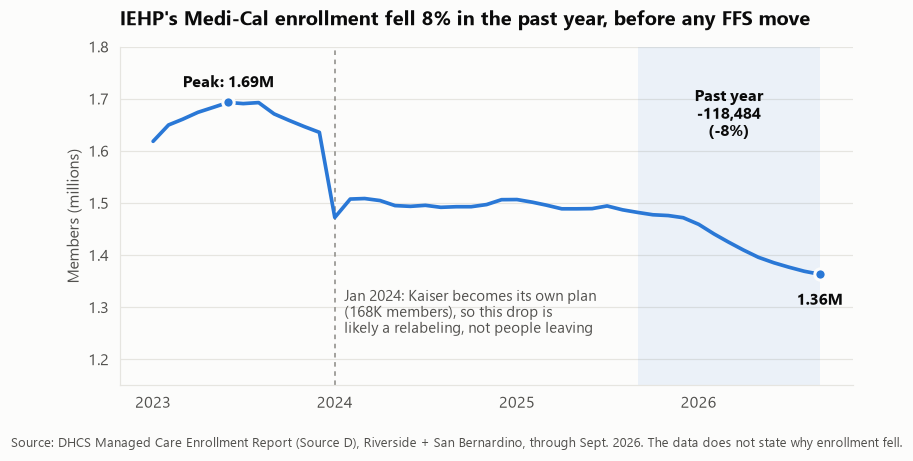

In [5]:
# IEHP trend from Source D
peak_month = iehp_by_month.idxmax()
peak = int(iehp_by_month.max())
sep_2025 = int(iehp_by_month["2025-09"])
jan_2026 = int(iehp_by_month["2026-01"])
pace = (source_d_total - jan_2026) / 8
projected_dec = source_d_total + 3 * pace

dec_2023, jan_2024 = int(iehp_by_month["2023-12"]), int(iehp_by_month["2024-01"])
step = dec_2023 - jan_2024
kaiser_start = int(kaiser_by_month["2024-01"])
all_change = int(all_plans_by_month["2024-01"] - all_plans_by_month["2023-12"])

print(f"Peak: {peak:,} in {peak_month}")
print(f"Total change since peak: {source_d_total - peak:,} ({source_d_total / peak - 1:.1%})")
print(f"  One-month drop, Dec 2023 to Jan 2024: {-step:,}")
print(f"  Kaiser's first month as its own plan, Jan 2024: {kaiser_start:,}")
print(f"  All plans in both counties, same month: {all_change:+,}")
print(f"Change since Jan 2024 (after the Kaiser step): {source_d_total - jan_2024:,}")
print(f"Change, Sep 2025 to Sep 2026: {source_d_total - sep_2025:,} ({source_d_total / sep_2025 - 1:.1%})")
print(f"Average monthly change, Jan to Sep 2026: {pace:,.0f}")
print(f"WHAT-IF: if that pace held, Dec 2026 would be about {projected_dec:,.0f}")

trend = iehp_by_month["2023-01":].copy()
trend.index = pd.to_datetime(trend.index + "-01")
peak_date, last_date = pd.Timestamp(peak_month + "-01"), trend.index[-1]
year_ago = pd.Timestamp("2025-09-01")

fig, ax = plt.subplots(figsize=(8.6, 4))
ax.axvspan(year_ago, last_date, color=BLUE, alpha=0.08, linewidth=0)
ax.axvline(pd.Timestamp("2024-01-01"), color=GRAY, linewidth=1, linestyle=(0, (3, 3)))
ax.plot(trend.index, trend / 1e6, color=BLUE, linewidth=2.4, solid_capstyle="round")
ax.scatter([peak_date, last_date], [peak / 1e6, trend.iloc[-1] / 1e6], s=55, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
ax.annotate(f"Peak: {peak/1e6:.2f}M", (peak_date, peak / 1e6), xytext=(0, 10), textcoords="offset points", ha="center", fontweight="bold")
ax.annotate(f"{source_d_total/1e6:.2f}M", (last_date, trend.iloc[-1] / 1e6), xytext=(0, -20), textcoords="offset points", ha="center", fontweight="bold")
ax.text(pd.Timestamp("2024-01-20"), 1.335, f"Jan 2024: Kaiser becomes its own plan\n({kaiser_start/1e3:,.0f}K members), so this drop is\nlikely a relabeling, not people leaving",
        color=MUTED, fontsize=9.5, va="top")
ax.text(year_ago + (last_date - year_ago) / 2, 1.72, f"Past year\n{source_d_total - sep_2025:+,.0f}\n({source_d_total / sep_2025 - 1:.0%})",
        color=INK, ha="center", va="top", fontweight="bold", fontsize=10.5)
ax.set_title(f"IEHP's Medi-Cal enrollment fell {1 - source_d_total / sep_2025:.0%} in the past year, before any FFS move", pad=14)
ax.set_ylabel("Members (millions)")
ax.set_ylim(1.15, 1.8)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(axis="x", visible=False)
fig.text(0.01, -0.03, "Source: DHCS Managed Care Enrollment Report (Source D), Riverside + San Bernardino, through Sept. 2026. The data does not state why enrollment fell.",
         color=MUTED, fontsize=8.5)
fig.savefig(OUTPUT_DIR / "iehp_enrollment_trend.png")
plt.show()

**Reading the trend carefully**

- **Do not say "IEHP lost 330K members."** About 163K of that drop happened in one month, January 2024, the same month Kaiser first appears as its own plan with about 168K members. Total enrollment across all plans in the two counties barely moved that month. So this step looks like members being relabeled to Kaiser, not leaving Medi-Cal. The file does not state the cause, so call it the *likely* explanation.
- **Safe number to use:** enrollment fell about 118K, or 8%, from September 2025 to September 2026.
- **Why it matters:** the transition has not started, so this decline is not caused by it. The group moving on January 1 may be smaller than a September count suggests, which is the workbook's reason for the 10% low case.

In [6]:
# How much would the FFS population grow in the two counties?
rows = []
for name, share in [("Low", I["share_low"]), ("Middle", I["share_mid"]), ("High", I["share_high"])]:
    moved = source_d_total * share
    rows.append({"Scenario": name, "Members moved": round(moved),
                 "FFS members after": round(ffs_today + moved),
                 "Times today's FFS": round((ffs_today + moved) / ffs_today, 1)})
b_all = pd.read_csv(SOURCE_B, dtype="string", encoding="utf-8-sig", keep_default_na=False)
ffs_rows = b_all[(b_all["Health Plan"] == "Fee-for-Service") & b_all["County"].isin(COUNTIES)]
ffs_jan_2024 = int(to_count(ffs_rows.loc[ffs_rows["Month of Eligibility"] == "2024-01", "Total Eligibles"]).sum())
print(f"Already in FFS today (Source B, {MONTH}): {ffs_today:,}")
print(f"For context, FFS in January 2024 (Source B): {ffs_jan_2024:,}. Today's level is low, so compare with care.")
pd.DataFrame(rows).set_index("Scenario")

Already in FFS today (Source B, 2026-09): 99,206
For context, FFS in January 2024 (Source B): 187,174. Today's level is low, so compare with care.


,Members moved,FFS members after,Times today's FFS
Scenario,,,
Low,136330,235536,2.4
Middle,194758,293964,3.0
High,245395,344601,3.5


## 4. Rebuild the workbook's model

One function reproduces "Segment & Cost Scenarios" Steps 3 to 6. Changing an argument is the same as changing a yellow cell in the workbook.

**The logic in plain English**
- **Revenue lost** = members × blended monthly payment × 12, plus one-time maternity payments.
- **Medical bills avoided** = revenue × medical cost share × how costly the leaving group is compared with what the payment expects.
- **Variable operating costs avoided** = revenue × operating share × the part that is not fixed.
- **Net effect** = avoided costs minus revenue lost.

In [7]:
def run_model(members, *, use_sis_rates=False, leaving_chronic=None, **changes):
    """Annual effect on IEHP and the State. Keyword changes override workbook inputs."""
    p = {**I, **changes}
    leaving_chronic = p["share_chronic"] if leaving_chronic is None else leaving_chronic

    # Step 3: member mix
    total = p["prog_child"] + p["prog_19_25"] + p["prog_26_49"] + p["prog_50_plus"]
    children = p["prog_child"] / total
    older = p["prog_50_plus"] / total * p["share_65_plus"]
    disabled = (1 - children - older) * p["share_disabled"]
    other_adults = 1 - children - older - disabled

    # Step 2: payment rates
    prefix = "sis" if use_sis_rates else "rate"
    pay_child, pay_spd = p[f"{prefix}_child"], p[f"{prefix}_spd"]
    pay_adult = p["share_parent"] * p[f"{prefix}_adult"] + (1 - p["share_parent"]) * p[f"{prefix}_aca"]
    blended = children * pay_child + (older + disabled) * pay_spd + other_adults * pay_adult

    # Cost factors: healthy and chronic adults average 1.0 at the State's assumed mix
    healthy_factor = 1 / (p["share_chronic"] * p["chronic_cost_ratio"] + 1 - p["share_chronic"])
    chronic_factor = healthy_factor * p["chronic_cost_ratio"]
    adult_factor = leaving_chronic * chronic_factor + (1 - leaving_chronic) * healthy_factor
    cost_factor = (children * pay_child + (older + disabled) * pay_spd
                   + other_adults * pay_adult * adult_factor) / blended

    # Step 5: results
    revenue_monthly = members * blended * 12
    revenue_maternity = members * p["deliveries_per_1000"] / 1000 * p["rate_maternity"]
    revenue = revenue_monthly + revenue_maternity
    medical = revenue_monthly * p["medical_share"] * cost_factor + revenue_maternity * p["medical_share"]
    variable = revenue * p["operating_share"] * (1 - p["fixed_share"])
    net = -revenue + medical + variable
    stranded = -revenue * p["operating_share"] * p["fixed_share"]

    return {
        "members": members, "blended_payment": blended, "cost_factor": cost_factor,
        "revenue_lost": revenue, "medical_avoided": medical, "variable_avoided": variable,
        "net_iehp": net, "stranded_fixed": stranded, "margin_given_up": net - stranded,
        "state_year1": revenue - medical, "state_year2": revenue - medical * (1 + p["extra_cost_year2"]),
    }

scenarios = {"Low": I["share_low"], "Middle": I["share_mid"], "High": I["share_high"]}
base = {k: run_model(source_d_total * s) for k, s in scenarios.items()}

### Check: does the rebuild match the workbook?

If this cell passes, every number below is the same as what you would get by typing into the workbook's yellow cells.

In [8]:
checks = []
def check(label, ours, cell):
    wb_value = sc[cell].value
    checks.append({"Item": label, "Cell": cell, "Workbook": wb_value, "Notebook": ours, "Diff": abs(ours - wb_value)})

for col, name in zip("BCD", ["Low", "Middle", "High"]):
    r = base[name]
    check(f"{name}: members", r["members"], f"{col}63")
    check(f"{name}: revenue lost", r["revenue_lost"], f"{col}66")
    check(f"{name}: medical avoided", r["medical_avoided"], f"{col}67")
    check(f"{name}: variable avoided", r["variable_avoided"], f"{col}68")
    check(f"{name}: net IEHP", r["net_iehp"], f"{col}69")
    check(f"{name}: stranded fixed", r["stranded_fixed"], f"{col}70")
    check(f"{name}: State year 1", r["state_year1"], f"{col}77")
    check(f"{name}: State year 2+", r["state_year2"], f"{col}79")

mid_members = base["Middle"]["members"]
for col, chronic in zip("BCD", [I["chronic_healthier"], I["share_chronic"], I["chronic_sicker"]]):
    r = run_model(mid_members, leaving_chronic=chronic)
    check(f"Mix {col}: net IEHP", r["net_iehp"], f"{col}90")
    check(f"Mix {col}: State year 1", r["state_year1"], f"{col}91")
check("Blended monthly payment", base["Middle"]["blended_payment"], "E48")

check_table = pd.DataFrame(checks)
assert check_table["Diff"].max() < 1, check_table.sort_values("Diff").tail()
print(f"PASS: {len(check_table)} workbook cells reproduced. Largest difference: ${check_table['Diff'].max():.6f}")

PASS: 31 workbook cells reproduced. Largest difference: $0.000000


## 5. Results: low, middle and high (workbook's default assumptions)

In [9]:
rows = {
    "Affected members": "members", "Revenue lost": "revenue_lost",
    "Medical bills avoided": "medical_avoided", "Variable operating costs avoided": "variable_avoided",
    "NET EFFECT ON IEHP": "net_iehp", "  of which stranded fixed costs": "stranded_fixed",
    "  of which operating margin": "margin_given_up",
}
results = pd.DataFrame({
    name: {label: (f"{r[key]:,.0f}" if key == "members" else money(r[key], 1)) for label, key in rows.items()}
    for name, r in base.items()
})
pd.DataFrame({n: {k: r[k] for k in rows.values()} for n, r in base.items()}).to_csv(OUTPUT_DIR / "scenario_results.csv")
results

,Low,Middle,High
Affected members,"136,330","194,758","245,395"
Revenue lost,$1.13B,$1.61B,$2.03B
Medical bills avoided,$1.07B,$1.53B,$1.92B
Variable operating costs avoided,$26.9M,$38.5M,$48.5M
NET EFFECT ON IEHP,-$33.3M,-$47.6M,-$60.0M
of which stranded fixed costs,-$40.4M,-$57.7M,-$72.7M
of which operating margin,$7.0M,$10.0M,$12.7M


For every $100 of revenue lost: $94.66 of medical bills go away, $2.38 of variable overhead goes away, IEHP is $2.95 worse off.


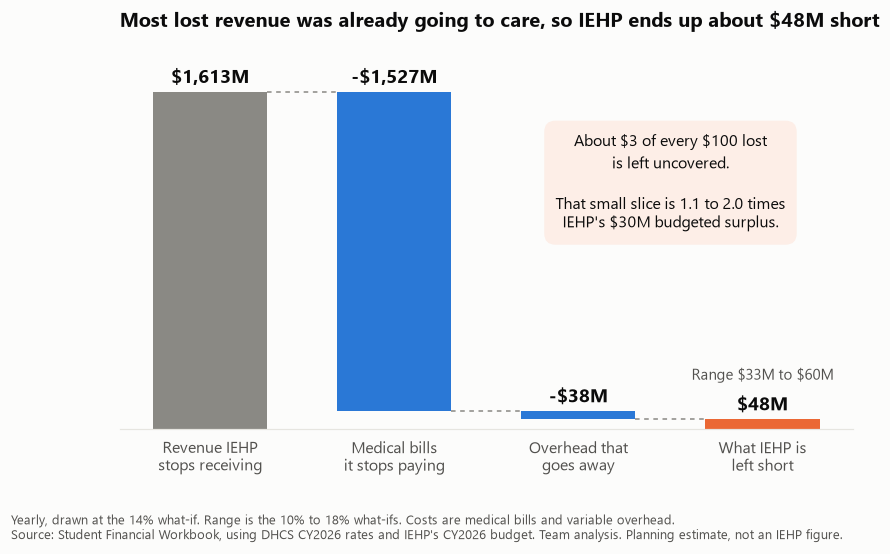

In [10]:
# Where each $100 of lost revenue goes
med_per_100 = I["medical_share"] * 100
var_per_100 = I["operating_share"] * (1 - I["fixed_share"]) * 100
stuck_per_100 = 100 - med_per_100 - var_per_100
print(f"For every $100 of revenue lost: ${med_per_100:.2f} of medical bills go away, "
      f"${var_per_100:.2f} of variable overhead goes away, IEHP is ${stuck_per_100:.2f} worse off.")

# Waterfall: start with revenue lost, take away the costs that leave too, see what is left
L, M, H = base["Low"], base["Middle"], base["High"]
revenue, medical, variable, short = M["revenue_lost"] / 1e6, M["medical_avoided"] / 1e6, M["variable_avoided"] / 1e6, -M["net_iehp"] / 1e6
assert abs(revenue - medical - variable - short) < 1e-6
budget_surplus = SURPLUS_PMPM * I["iehp_all_lines"] * 12

steps = [
    ("Revenue IEHP\nstops receiving", 0, revenue, GRAY, f"${revenue:,.0f}M"),
    ("Medical bills\nit stops paying", revenue - medical, revenue, BLUE, f"-${medical:,.0f}M"),
    ("Overhead that\ngoes away", short, short + variable, BLUE, f"-${variable:,.0f}M"),
    ("What IEHP is\nleft short", 0, short, ORANGE, f"${short:,.0f}M"),
]
fig, ax = plt.subplots(figsize=(8.6, 4.5))
for i, (label, bottom, top, color, text) in enumerate(steps):
    ax.bar(i, top - bottom, bottom=bottom, width=0.62, color=color)
    ax.annotate(text, (i, top), xytext=(0, 6), textcoords="offset points", ha="center", fontweight="bold", fontsize=12.5)
    if i < len(steps) - 1:
        level = steps[i + 1][2]
        ax.plot([i + 0.31, i + 0.69], [level, level], color=GRAY, linewidth=1, linestyle=(0, (3, 3)))
ax.annotate(f"Range ${-L['net_iehp']/1e6:.0f}M to ${-H['net_iehp']/1e6:.0f}M", (3, short), xytext=(0, 26), textcoords="offset points",
            ha="center", color=MUTED, fontsize=9.5)
ax.text(2.5, 1180, f"About $3 of every $100 lost\nis left uncovered.\n\nThat small slice is {-L['net_iehp']/budget_surplus:.1f} to {-H['net_iehp']/budget_surplus:.1f} times\nIEHP's ${budget_surplus/1e6:.0f}M budgeted surplus.",
        ha="center", va="center", fontsize=10.5, linespacing=1.35,
        bbox=dict(boxstyle="round,pad=0.7", facecolor="#fdeee7", edgecolor="none"))
ax.set_xticks(range(4), [s[0] for s in steps])
ax.set_ylim(0, revenue * 1.13)
ax.yaxis.set_visible(False)
ax.grid(False)
ax.spines["left"].set_visible(False)
ax.set_title(f"Most lost revenue was already going to care, so IEHP ends up about ${short:.0f}M short", pad=14)
fig.text(0.01, -0.06, "Yearly, drawn at the 14% what-if. Range is the 10% to 18% what-ifs. Costs are medical bills and variable overhead.\n"
         "Source: Student Financial Workbook, using DHCS CY2026 rates and IEHP's CY2026 budget. Team analysis. Planning estimate, not an IEHP figure.",
         color=MUTED, fontsize=8.5, va="top")
fig.savefig(OUTPUT_DIR / "waterfall_middle_case.png")
plt.show()

## 6. Who leaves matters more than how many

The workbook runs healthier, base and sicker mixes only for the middle case. This grid extends that to all three headcounts.

**Important:** IEHP does not choose who leaves. The State's rules decide that. This is a risk to *estimate*, and IEHP can do that with its own claims data before January 1. No one should ever use this to treat members differently.

In [11]:
mixes = {"Healthier leave (40% chronic)": I["chronic_healthier"], "Base (50% chronic)": I["share_chronic"], "Sicker leave (65% chronic)": I["chronic_sicker"]}
grid_raw = pd.DataFrame({
    s_name: {m_name: run_model(source_d_total * s, leaving_chronic=c)["net_iehp"] for m_name, c in mixes.items()}
    for s_name, s in scenarios.items()
})
grid_raw.to_csv(OUTPUT_DIR / "net_by_share_and_mix.csv")

mix_swing = grid_raw.loc["Sicker leave (65% chronic)", "Middle"] - grid_raw.loc["Healthier leave (40% chronic)", "Middle"]
headcount_swing = base["Low"]["net_iehp"] - base["High"]["net_iehp"]
print(f"Swing from patient mix at 14%: {money(mix_swing)}")
print(f"Swing from headcount at base mix: {money(headcount_swing)}")
print(f"Patient mix moves the answer {mix_swing / headcount_swing:.1f} times as much as headcount\n")
grid_raw.map(money)

Swing from patient mix at 14%: $230M
Swing from headcount at base mix: $27M
Patient mix moves the answer 8.6 times as much as headcount



,Low,Middle,High
Healthier leave (40% chronic),-$98M,-$140M,-$176M
Base (50% chronic),-$33M,-$48M,-$60M
Sicker leave (65% chronic),$63M,$91M,$114M


## 7. Which assumptions move the answer most?

Each row changes **one** assumption from the middle case and keeps the rest. Ranges come from the workbook's own notes ("test 15%–35%" and so on).

`Chronic cost ratio` is left out on purpose: at the base mix the model rescales it so healthy and chronic adults average 1.0, so changing it alone does nothing.

In [12]:
n = source_d_total * I["share_mid"]
base_net = base["Middle"]["net_iehp"]

tests = [
    # label, low-side kwargs, high-side kwargs, what the two ends are
    ("Who leaves (chronic share)", dict(leaving_chronic=.40), dict(leaving_chronic=.65), "40% vs 65%"),
    ("Medical cost share", dict(medical_share=.888), dict(), "88.8% (State view) vs 94.7% (IEHP)"),
    ("Share of members affected", dict(members=source_d_total * I["share_high"]), dict(members=source_d_total * I["share_low"]), "18% vs 10%"),
    ("Fixed share of operating costs", dict(fixed_share=.8), dict(fixed_share=.4), "80% vs 40%"),
    ("Priced as parents/caretakers", dict(share_parent=.2), dict(share_parent=.4), "20% vs 40%"),
    ("Share of 50+ who are 65+", dict(share_65_plus=.35), dict(share_65_plus=.15), "35% vs 15%"),
    ("Disability share of adults", dict(share_disabled=.04), dict(share_disabled=.01), "4% vs 1%"),
    ("Deliveries per 1,000", dict(deliveries_per_1000=20), dict(deliveries_per_1000=10), "20 vs 10"),
]

rows = []
for label, a, b_, ends in tests:
    a_n, b_n = a.pop("members", n), b_.pop("members", n)
    lo, hi = run_model(a_n, **a)["net_iehp"], run_model(b_n, **b_)["net_iehp"]
    rows.append({"Assumption": label, "Tested": ends, "Worse end": min(lo, hi), "Better end": max(lo, hi)})
sens = pd.DataFrame(rows)
sens["Swing"] = sens["Better end"] - sens["Worse end"]
sens = sens.sort_values("Swing", ascending=False).reset_index(drop=True)
sens.to_csv(OUTPUT_DIR / "sensitivity.csv", index=False)

show = sens.copy()
for c in ["Worse end", "Better end", "Swing"]:
    show[c] = show[c].map(lambda v: money(v, 1))
print(f"Middle case net effect: {money(base_net, 1)}")
show

Middle case net effect: -$47.6M


,Assumption,Tested,Worse end,Better end,Swing
0,Who leaves (chronic share),40% vs 65%,-$139.8M,$90.6M,$230.4M
1,Medical cost share,88.8% (State view) vs 94.7% (IEHP),-$142.2M,-$47.6M,$94.6M
2,Fixed share of operating costs,80% vs 40%,-$66.9M,-$28.4M,$38.5M
3,Share of members affected,18% vs 10%,-$60.0M,-$33.3M,$26.7M
4,Share of 50+ who are 65+,35% vs 15%,-$50.2M,-$45.0M,$5.2M
5,Priced as parents/caretakers,20% vs 40%,-$49.4M,-$45.9M,$3.5M
6,Disability share of adults,4% vs 1%,-$49.1M,-$46.9M,$2.2M
7,"Deliveries per 1,000",20 vs 10,-$47.9M,-$47.4M,$0.5M


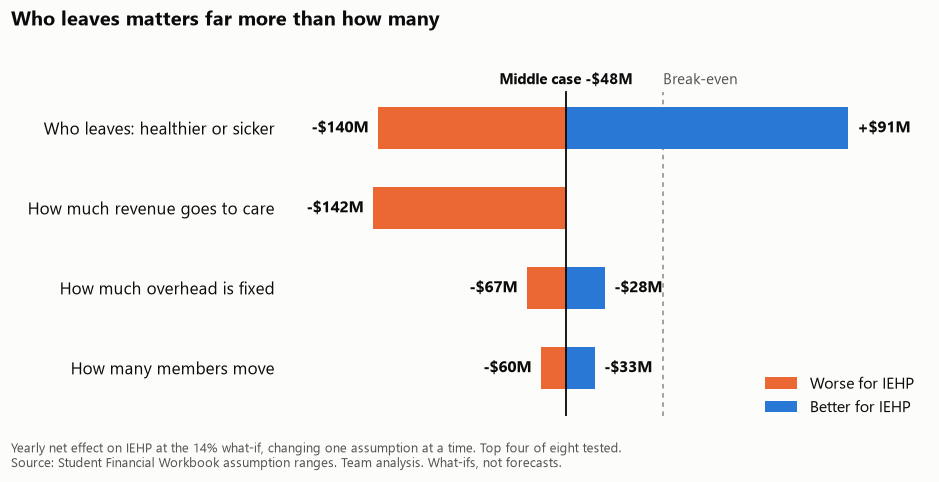

In [13]:
plain_labels = {
    "Who leaves (chronic share)": "Who leaves: healthier or sicker",
    "Medical cost share": "How much revenue goes to care",
    "Fixed share of operating costs": "How much overhead is fixed",
    "Share of members affected": "How many members move",
}
plot = sens[sens["Assumption"].isin(plain_labels)].iloc[::-1].copy()
plot["Label"] = plot["Assumption"].map(plain_labels)
y = np.arange(len(plot))
base_m = base_net / 1e6

fig, ax = plt.subplots(figsize=(8.6, 3.9))
ax.barh(y, (plot["Worse end"] - base_net).clip(upper=0) / 1e6, left=base_m, height=0.52, color=ORANGE, label="Worse for IEHP")
ax.barh(y, (plot["Better end"] - base_net).clip(lower=0) / 1e6, left=base_m, height=0.52, color=BLUE, label="Better for IEHP")
top = len(plot) - 0.55
ax.plot([base_m, base_m], [-0.6, top], color=INK, linewidth=1.2, zorder=3)
ax.plot([0, 0], [-0.6, top], color=GRAY, linewidth=1, linestyle=(0, (3, 3)), zorder=0)
for yi, (_, row) in zip(y, plot.iterrows()):
    ax.annotate(money(row["Worse end"]), (row["Worse end"] / 1e6, yi), xytext=(-6, 0), textcoords="offset points", ha="right", va="center", fontweight="bold")
    if row["Better end"] > base_net:
        sign = "+" if row["Better end"] > 0 else ""
        ax.annotate(sign + money(row["Better end"]), (row["Better end"] / 1e6, yi), xytext=(6, 0), textcoords="offset points", ha="left", va="center", fontweight="bold")
ax.text(base_m, top + 0.06, f"Middle case {money(base_net)}", ha="center", va="bottom", fontsize=9.5, fontweight="bold", color=INK)
ax.text(0, top + 0.06, "Break-even", ha="left", va="bottom", fontsize=9.5, color=MUTED)
ax.set_yticks(y, plot["Label"])
ax.tick_params(axis="y", labelcolor=INK, labelsize=11)
ax.set_xlim(-185, 130)
ax.set_ylim(-0.6, len(plot) - 0.2)
ax.xaxis.set_visible(False)
ax.grid(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(False)
fig.subplots_adjust(left=0.30, right=0.98, top=0.86, bottom=0.04)
fig.text(0.01, 0.95, "Who leaves matters far more than how many", fontsize=13, fontweight="bold")
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, -0.04))
fig.text(0.01, -0.02, "Yearly net effect on IEHP at the 14% what-if, changing one assumption at a time. Top four of eight tested.\n"
         "Source: Student Financial Workbook assumption ranges. Team analysis. What-ifs, not forecasts.",
         color=MUTED, fontsize=8.5, va="top")
fig.savefig(OUTPUT_DIR / "sensitivity_tornado.png")
plt.show()

In [14]:
# Does the member-count choice from Section 3 matter?
bases = {
    "Source C: fact sheet, Medi-Cal only": source_c,
    "Source B: IEHP-labeled": source_b_iehp,
    "Source D: chosen": source_d_total,
    "WHAT-IF: Source D pace held to Dec 2026": projected_dec,
}
pd.DataFrame({
    label: {"Members at 14%": f"{v * I['share_mid']:,.0f}",
            "Revenue lost": money(run_model(v * I["share_mid"])["revenue_lost"]),
            "Net IEHP": money(run_model(v * I["share_mid"])["net_iehp"], 1)}
    for label, v in bases.items()
}).T

,Members at 14%,Revenue lost,Net IEHP
"Source C: fact sheet, Medi-Cal only","188,855",$1.56B,-$46.2M
Source B: IEHP-labeled,"191,492",$1.59B,-$46.8M
Source D: chosen,"194,758",$1.61B,-$47.6M
WHAT-IF: Source D pace held to Dec 2026,"189,628",$1.57B,-$46.4M


## 8. How big is the hit? Fixed costs and the budgeted surplus

The net hit looks small next to about $7.3B of revenue. A better comparison is IEHP's thin budget.

The workbook's note in row 56 of "Segment & Cost Scenarios" says IEHP budgets a surplus of $1.82 per member per month in CY2026, and that it comes from non-operating income such as investments. Revenue minus medical minus operating is slightly negative.

**Gap in our files:** we do not have IEHP's reserves, so we cannot say how long it could absorb a hit. The surplus comparison shows scale only. The Finance Committee packet may have this.

In [15]:
all_lines = I["iehp_all_lines"]

operating_margin_pmpm = I["pmpm_revenue"] - I["pmpm_medical"] - I["pmpm_operating"]
budget_surplus = SURPLUS_PMPM * all_lines * 12
annual_medical = I["annual_medical_revenue"]

print(f"Operating result per member per month, CY2026 budget: -${abs(operating_margin_pmpm):.2f}")
print(f"Budgeted annual surplus: ${SURPLUS_PMPM} x {all_lines:,} members x 12 = {money(budget_surplus, 1)}\n")

pd.DataFrame({
    name: {
        "Net hit": money(r["net_iehp"], 1),
        "As % of annualized Medi-Cal revenue": f"{-r['net_iehp'] / annual_medical:.2%}",
        "Times the budgeted surplus": f"{-r['net_iehp'] / budget_surplus:.1f}x",
    } for name, r in base.items()
})

Operating result per member per month, CY2026 budget: -$3.09
Budgeted annual surplus: $1.82 x 1,394,246 members x 12 = $30.5M



,Low,Middle,High
Net hit,-$33.3M,-$47.6M,-$60.0M
As % of annualized Medi-Cal revenue,0.46%,0.65%,0.82%
Times the budgeted surplus,1.1x,1.6x,2.0x


### The metric for the financial recommendation: fixed cost per remaining member

The workbook estimates stranded cost as a share of *revenue lost*, which assumes these members carry overhead in proportion to their higher payment. A second way is per *member*: every member carries the same overhead. We show both, because they bracket the answer.

We use IEHP's all-lines membership here because the $29.58 operating cost is an all-lines figure. The 60% fixed share is an assumption.

In [16]:
fixed_pmpm = I["pmpm_operating"] * I["fixed_share"]
fixed_pool = fixed_pmpm * all_lines * 12
print(f"Fixed operating cost today: ${fixed_pmpm:.2f} per member per month, about {money(fixed_pool)} a year (60% assumption)")
print(f"Tested at 40% to 80% fixed: {money(fixed_pool * .4 / .6)} to {money(fixed_pool * .8 / .6)} a year\n")

rows = {}
for name, r in base.items():
    remaining = all_lines - r["members"]
    after = fixed_pool / remaining / 12
    rows[name] = {
        "Remaining members": f"{remaining:,.0f}",
        "Fixed cost per member per month, no action": f"${after:.2f}",
        "Increase": f"{after / fixed_pmpm - 1:.1%}",
        "Stranded cost, per-member method": money(-r["members"] * fixed_pmpm * 12, 1),
        "Stranded cost, workbook method": money(r["stranded_fixed"], 1),
    }
fixed_table = pd.DataFrame(rows)
fixed_table.to_csv(OUTPUT_DIR / "fixed_cost_metric.csv")
fixed_table

Fixed operating cost today: $17.75 per member per month, about $297M a year (60% assumption)
Tested at 40% to 80% fixed: $198M to $396M a year



,Low,Middle,High
Remaining members,"1,257,916","1,199,488","1,148,851"
"Fixed cost per member per month, no action",$19.67,$20.63,$21.54
Increase,10.8%,16.2%,21.4%
"Stranded cost, per-member method",-$29.0M,-$41.5M,-$52.3M
"Stranded cost, workbook method",-$40.4M,-$57.7M,-$72.7M


### Sizing a trigger plan

This answers: *how much fixed cost must IEHP remove to keep fixed cost per member within a chosen limit?*

The 0%, +5% and +10% limits are **examples for the team to choose from, not sourced figures**. Label them as your own assumption. Reductions can include moving staff into transition support and not refilling open roles, which should come before cuts that touch remaining members.

In [17]:
limits = {"Hold at today's level": 0.00, "Allow +5%": 0.05, "Allow +10%": 0.10}
rows = {}
for label, limit in limits.items():
    row = {}
    for name, r in base.items():
        remaining = all_lines - r["members"]
        target_pool = fixed_pmpm * (1 + limit) * remaining * 12
        row[name] = money(max(fixed_pool - target_pool, 0), 1)
    rows[label] = row
trigger_table = pd.DataFrame(rows).T
trigger_table.index.name = "Annual fixed cost to remove"
trigger_table.to_csv(OUTPUT_DIR / "trigger_sizing.csv")
trigger_table

,Low,Middle,High
Annual fixed cost to remove,,,
Hold at today's level,$29.0M,$41.5M,$52.3M
Allow +5%,$15.6M,$28.7M,$40.0M
Allow +10%,$2.2M,$15.9M,$27.8M


### Stoplight triggers

This turns the metric into decisions. **The green, yellow and red levels are team assumptions, not sourced figures.** The actions are a draft for the team to edit.

The percentage rise depends only on how many members leave, so it does not change if the 60% fixed share is wrong. The dollar amounts do.

In [18]:
YELLOW_AT, RED_AT = 0.05, 0.10   # TEAM ASSUMPTION: change these to test other levels
levels = pd.DataFrame({
    "Fixed cost per member per month": [f"Up to ${fixed_pmpm * (1 + YELLOW_AT):.2f}",
                                        f"${fixed_pmpm * (1 + YELLOW_AT):.2f} to ${fixed_pmpm * (1 + RED_AT):.2f}",
                                        f"Above ${fixed_pmpm * (1 + RED_AT):.2f}"],
    "Rise from today": [f"Up to {YELLOW_AT:.0%}", f"{YELLOW_AT:.0%} to {RED_AT:.0%}", f"Above {RED_AT:.0%}"],
    "Draft response": ["Keep tracking monthly",
                       "Redeploy staff to transition work and hold open roles",
                       "CFO takes a cost plan to the Finance Committee: vendor review, then structural changes"],
}, index=["Green", "Yellow", "Red"])

def stoplight(rise):
    return "Red" if rise > RED_AT else "Yellow" if rise > YELLOW_AT else "Green"

rows = {}
for name, r in base.items():
    rise = r["members"] / (all_lines - r["members"])
    to_green = fixed_pool - fixed_pmpm * (1 + YELLOW_AT) * (all_lines - r["members"]) * 12
    rows[name] = {"Rise with no action": f"{rise:.1%}", "Status with no action": stoplight(rise),
                  "Yearly fixed cost to remove to reach green": money(max(to_green, 0), 1)}
stoplight_results = pd.DataFrame(rows)
levels.to_csv(OUTPUT_DIR / "stoplight_levels.csv")
stoplight_results.to_csv(OUTPUT_DIR / "stoplight_results.csv")
display(levels)
stoplight_results

,Fixed cost per member per month,Rise from today,Draft response
Green,Up to $18.64,Up to 5%,Keep tracking monthly
Yellow,$18.64 to $19.52,5% to 10%,Redeploy staff to transition work and hold ope...
Red,Above $19.52,Above 10%,CFO takes a cost plan to the Finance Committee...


,Low,Middle,High
Rise with no action,10.8%,16.2%,21.4%
Status with no action,Red,Red,Red
Yearly fixed cost to remove to reach green,$15.6M,$28.7M,$40.0M


**Reading this:** at these sample levels, every scenario lands in red with no action, so waiting until January to react means starting in red. The low case is only just over the line, so the result depends on the levels the team chooses.

### Why growth alone cannot fix it

Fixed cost per member could also fall by adding members. This checks that idea against IEHP's other lines of business from the fact sheet (Source C). It is a size check only and ignores differences in margin between lines.

In [19]:
other_lines = DUALCHOICE + COVERED_CA
rows = {}
for name, r in base.items():
    after_growth = fixed_pool / (all_lines - r["members"] + other_lines) / 12
    rows[name] = {
        "Members leaving": f"{r['members']:,.0f}",
        "Members added if other lines DOUBLE": f"{other_lines:,}",
        "Share of the loss replaced": f"{other_lines / r['members']:.0%}",
        "Fixed cost per member after doubling": f"${after_growth:.2f}",
        "Still above today's level by": f"{after_growth / fixed_pmpm - 1:.1%}",
    }
growth_table = pd.DataFrame(rows)
growth_table.to_csv(OUTPUT_DIR / "growth_check.csv")
print(f"Today: DualChoice {DUALCHOICE:,} + Covered California {COVERED_CA:,} = {other_lines:,} members")
growth_table

Today: DualChoice 38,185 + Covered California 34,078 = 72,263 members


,Low,Middle,High
Members leaving,"136,330","194,758","245,395"
Members added if other lines DOUBLE,"72,263","72,263","72,263"
Share of the loss replaced,53%,37%,29%
Fixed cost per member after doubling,$18.60,$19.46,$20.26
Still above today's level by,4.8%,9.6%,14.2%


### Glide path: how fast stranded costs could shrink

This compares removing stranded fixed costs at different speeds. **The yearly paces are team assumptions.** Year 1 is held at the full amount, which is cautious, because any action taken before January 1 would lower it. It covers stranded fixed costs only.

Both stranded-cost estimates are shown, because they bracket the middle case.

In [20]:
paces = {"No action": 0, "Slow: 20% a year": .2, "Steady: 33% a year": 1/3, "Fast: 50% a year": .5}   # TEAM ASSUMPTION
low_est = M["members"] * fixed_pmpm * 12
high_est = -M["stranded_fixed"]

rows = {}
for name, pace in paces.items():
    left = [max(1 - pace * year, 0) for year in range(3)]
    rows[name] = {
        "Year 1": f"{money(low_est * left[0])} to {money(high_est * left[0])}",
        "Year 2": f"{money(low_est * left[1])} to {money(high_est * left[1])}",
        "Year 3": f"{money(low_est * left[2])} to {money(high_est * left[2])}",
        "3-year total": f"{money(low_est * sum(left))} to {money(high_est * sum(left))}",
    }
glide_table = pd.DataFrame(rows).T
glide_table.index.name = "Middle case"
glide_table.to_csv(OUTPUT_DIR / "glide_path.csv")
glide_table

,Year 1,Year 2,Year 3,3-year total
Middle case,,,,
No action,$41M to $58M,$41M to $58M,$41M to $58M,$124M to $173M
Slow: 20% a year,$41M to $58M,$33M to $46M,$25M to $35M,$100M to $138M
Steady: 33% a year,$41M to $58M,$28M to $38M,$14M to $19M,$83M to $115M
Fast: 50% a year,$41M to $58M,$21M to $29M,$0M to $0M,$62M to $87M


## 9. The State's side: why access protects everyone's numbers

The workbook estimates the State's gross gain before its own admin costs and before federal funding for emergency care. It assumes FFS pays the same prices and members use the same amount of care.

Yardley (slide 25): if access gets worse and care is delayed, the State's savings can shrink over time. This cell finds how much extra medical cost would erase the gain.

In [21]:
rows = {}
for name, r in base.items():
    rows[name] = {
        "State gain, year 1": money(r["state_year1"], 1),
        "State gain, year 2+ at +5% cost": money(r["state_year2"], 1),
    }
state_table = pd.DataFrame(rows)

m = base["Middle"]
break_even = m["state_year1"] / m["medical_avoided"]
print(f"Break-even: a {break_even:.1%} rise in medical cost erases the State's gain in this model.\n")
state_table

Break-even: a 5.6% rise in medical cost erases the State's gain in this model.



,Low,Middle,High
"State gain, year 1",$60.3M,$86.1M,$108.5M
"State gain, year 2+ at +5% cost",$6.8M,$9.7M,$12.3M


## 10. Cross-check: why do the two workbook tabs disagree on revenue?

The simple tab says about $0.8B to $1.1B. The detailed tab says about $1.1B to $2.0B. The gap is the assumed payment per member.

The workbook warns that adding the federal and state-only UIS rates together should be checked against the DHCS rate certification report before citing it. We could not check that from our files, so we show what happens with a lower rate.

In [22]:
blended = base["Middle"]["blended_payment"]
sis = run_model(n, use_sis_rates=True)
rows = [
    ("Simple tab B: unsourced guess", I["pmpm_simple_b"], I["rev_simple_b"], None),
    ("Simple tab: implied from revenue", I["pmpm_implied"], I["pmpm_implied"] * 12 * n, None),
    ("Simple tab A: IEHP all-lines budget", I["pmpm_simple_a"], I["rev_simple_a"], None),
    ("Detailed, WHAT-IF: SIS rates", sis["blended_payment"], sis["revenue_lost"], sis["net_iehp"]),
    ("Detailed tab: UIS rates added", blended, base["Middle"]["revenue_lost"], base["Middle"]["net_iehp"]),
]
xcheck = pd.DataFrame(rows, columns=["Method", "Monthly payment", "Revenue at about 14%", "Net IEHP"])
xcheck["Monthly payment"] = xcheck["Monthly payment"].map("${:,.2f}".format)
xcheck["Revenue at about 14%"] = xcheck["Revenue at about 14%"].map(money)
xcheck["Net IEHP"] = xcheck["Net IEHP"].map(lambda v: "not modeled" if pd.isna(v) else money(v, 1))

rev_share = base["Middle"]["revenue_lost"] / annual_medical
remaining_pmpm = (annual_medical - base["Middle"]["revenue_lost"]) / ((source_d_total - n) * 12)
print(f"Detailed tab: {I['share_mid']:.1%} of members would be {rev_share:.1%} of annualized Medi-Cal revenue.")
print(f"That leaves about ${remaining_pmpm:,.0f} per month for everyone else, compared with ${I['pmpm_implied']:,.2f} on average.")
print("Treat the top of the range with care. The annualized revenue is from H1 2025, while rates are CY2026.\n")
xcheck.set_index("Method")

Detailed tab: 14.3% of members would be 22.1% of annualized Medi-Cal revenue.
That leaves about $406 per month for everyone else, compared with $460.47 on average.
Treat the top of the range with care. The annualized revenue is from H1 2025, while rates are CY2026.



,Monthly payment,Revenue at about 14%,Net IEHP
Method,,,
Simple tab B: unsourced guess,$350.00,$793M,not modeled
Simple tab: implied from revenue,$460.47,$1.08B,not modeled
Simple tab A: IEHP all-lines budget,$496.33,$1.12B,not modeled
"Detailed, WHAT-IF: SIS rates",$560.86,$1.34B,-$39.5M
Detailed tab: UIS rates added,$678.45,$1.61B,-$47.6M


## 11. Assumption log

Put this on your sources slide or keep it as backup for judges' questions.

In [23]:
log = pd.DataFrame([
    ("IEHP Medi-Cal members", f"{source_d_total:,}", "Sourced", "Source D, Sep 2026 (preliminary)"),
    ("Share of members affected", "10% / 14.3% / 18%", "Assumption", "Case guide. Statewide 2M of 14M. Applied evenly"),
    ("State payment rates", "UIS federal + state-only parts added", "Sourced, reading unverified", "DHCS CY2026 rates, workbook Step 2"),
    ("Member mix", "Statewide program counts", "Sourced, then assumed", "About 1.28M of 2M. Same mix assumed for the rest"),
    ("65+ share of 50+ group", "25% (test 15–35%)", "Assumption", "Workbook B35"),
    ("Disability share of adults", "2% (test 1–4%)", "Assumption", "Workbook B36"),
    ("Priced as parents/caretakers", "30% (test 20–40%)", "Assumption", "Workbook B37"),
    ("Chronic share of adults", "50% (what-ifs 40%, 65%)", "Assumption, KFF basis", "Workbook B38, B84, D84"),
    ("Medical cost share", "94.7% (test 88.8%)", "Sourced, all lines", "IEHP CY2026 budget. Not UIS-specific"),
    ("Operating cost share", "6.0%", "Sourced, all lines", "IEHP CY2026 budget"),
    ("Fixed share of operating cost", "60% (test 40–80%)", "Assumption", "Workbook B59"),
    ("Extra FFS cost from year 2", "5% (test 0–10%)", "Assumption", "Workbook B78"),
    ("Stoplight levels", "Yellow above +5%, red above +10%", "Team assumption", "Examples only, Section 8"),
    ("Glide path paces", "20%, 33%, 50% a year", "Team assumption", "Examples only, Section 8"),
    ("Other lines of business", f"{other_lines:,} members", "Sourced", "IEHP Fact Sheet, Oct 2026"),
], columns=["Item", "Value", "Type", "Where it comes from"]).set_index("Item")
log.to_csv(OUTPUT_DIR / "assumption_log.csv")
log

,Value,Type,Where it comes from
Item,,,
IEHP Medi-Cal members,"1,363,303",Sourced,"Source D, Sep 2026 (preliminary)"
Share of members affected,10% / 14.3% / 18%,Assumption,Case guide. Statewide 2M of 14M. Applied evenly
State payment rates,UIS federal + state-only parts added,"Sourced, reading unverified","DHCS CY2026 rates, workbook Step 2"
Member mix,Statewide program counts,"Sourced, then assumed",About 1.28M of 2M. Same mix assumed for the rest
65+ share of 50+ group,25% (test 15–35%),Assumption,Workbook B35
Disability share of adults,2% (test 1–4%),Assumption,Workbook B36
Priced as parents/caretakers,30% (test 20–40%),Assumption,Workbook B37
Chronic share of adults,"50% (what-ifs 40%, 65%)","Assumption, KFF basis","Workbook B38, B84, D84"
Medical cost share,94.7% (test 88.8%),"Sourced, all lines",IEHP CY2026 budget. Not UIS-specific


## 12. Video-ready summary

These lines are generated from the results above, so they update if you change an assumption.

In [24]:
L, M, H = base["Low"], base["Middle"], base["High"]
worst = grid_raw.min().min()
best = grid_raw.max().max()
mid_after = fixed_pool / (all_lines - M["members"]) / 12

print(f"""
MEMBERS
  {L['members']:,.0f} to {H['members']:,.0f} IEHP members move (10% to 18% what-if; {M['members']:,.0f} at the statewide ratio).
  FFS members in the two counties grow {(ffs_today + L['members']) / ffs_today:.1f} to {(ffs_today + H['members']) / ffs_today:.1f} times from {ffs_today:,}.

MONEY
  Revenue at risk: {money(L['revenue_lost'])} to {money(H['revenue_lost'])} a year.
  Net hit, base mix: {money(L['net_iehp'])} to {money(H['net_iehp'])} a year.
  That is {-L['net_iehp'] / budget_surplus:.1f} to {-H['net_iehp'] / budget_surplus:.1f} times the {money(budget_surplus)} budgeted surplus.
  Full range with patient mix: {money(worst)} to +{money(best)}.

WHAT DRIVES IT
  Patient mix moves the result {mix_swing / headcount_swing:.1f} times as much as headcount.
  Stranded fixed cost, middle case: {money(-M['members'] * fixed_pmpm * 12)} (per member) to {money(M['stranded_fixed'])} (workbook).

METRIC FOR THE FINANCIAL RECOMMENDATION
  Fixed cost per remaining member: ${fixed_pmpm:.2f} today, ${mid_after:.2f} in the middle case with no action ({mid_after / fixed_pmpm - 1:+.1%}).
  Growth alone can't close it: doubling IEHP's other lines adds {other_lines:,} members, against {L['members']:,.0f} to {H['members']:,.0f} leaving.

WHY ACCESS PROTECTS THE MONEY
  A {break_even:.1%} rise in medical cost erases the State's modeled gain.
""")

saved = sorted(p.name for p in OUTPUT_DIR.iterdir())
print("Saved to analysis_outputs/financial/:", ", ".join(saved))


MEMBERS
  136,330 to 245,395 IEHP members move (10% to 18% what-if; 194,758 at the statewide ratio).
  FFS members in the two counties grow 2.4 to 3.5 times from 99,206.

MONEY
  Revenue at risk: $1.13B to $2.03B a year.
  Net hit, base mix: -$33M to -$60M a year.
  That is 1.1 to 2.0 times the $30M budgeted surplus.
  Full range with patient mix: -$176M to +$114M.

WHAT DRIVES IT
  Patient mix moves the result 8.6 times as much as headcount.
  Stranded fixed cost, middle case: -$41M (per member) to -$58M (workbook).

METRIC FOR THE FINANCIAL RECOMMENDATION
  Fixed cost per remaining member: $17.75 today, $20.63 in the middle case with no action (+16.2%).
  Growth alone can't close it: doubling IEHP's other lines adds 72,263 members, against 136,330 to 245,395 leaving.

WHY ACCESS PROTECTS THE MONEY
  A 5.6% rise in medical cost erases the State's modeled gain.

Saved to analysis_outputs/financial/: assumption_log.csv, fixed_cost_metric.csv, glide_path.csv, growth_check.csv, iehp_enro

### 12b. IEHP's own estimate: 119,600 members (from the Q&A email)

After the guide's 10% to 18% what-ifs were set, IEHP shared its own estimate of **119,600** transitioning members. We run it through the same model. It is **8.8% of Source D enrollment, below the guide's 10% low case**, so it becomes the base case and the guide's cases become sensitivity around it.

**Different counts, different jobs:** 172,459 is DHCS's June 2026 UIS count for both counties (all plans and FFS). 119,600 is IEHP's estimate of its own members who move. Neither is a final January count.

Mix and cost assumptions are still the workbook's, not IEHP's.

In [ ]:
IEHP_ESTIMATE = 119_600          # IEHP via Q&A email
UIS_TWO_COUNTIES_JUNE = 172_459  # DHCS June 2026 via Q&A email

est = run_model(IEHP_ESTIMATE)
est_remaining = all_lines - IEHP_ESTIMATE
est_rise = IEHP_ESTIMATE / est_remaining
est_after = fixed_pool / est_remaining / 12
est_mix = {name: run_model(IEHP_ESTIMATE, leaving_chronic=c)["net_iehp"] for name, c in mixes.items()}

iehp_case = pd.Series({
    "Members": f"{IEHP_ESTIMATE:,}",
    "Share of Source D enrollment": f"{IEHP_ESTIMATE / source_d_total:.1%}",
    "Share of county UIS count (derived ratio)": f"{IEHP_ESTIMATE / UIS_TWO_COUNTIES_JUNE:.1%}",
    "Revenue lost": money(est["revenue_lost"]),
    "Medical bills avoided": money(est["medical_avoided"]),
    "Variable operating costs avoided": money(est["variable_avoided"]),
    "NET EFFECT ON IEHP": money(est["net_iehp"], 1),
    "Times the budgeted surplus": f"{-est['net_iehp'] / budget_surplus:.1f}x",
    "Stranded fixed cost, workbook method": money(est["stranded_fixed"], 1),
    "Stranded fixed cost, per-member method": money(-IEHP_ESTIMATE * fixed_pmpm * 12, 1),
    "Fixed cost per member per month, no action": f"${est_after:.2f} ({est_after / fixed_pmpm - 1:+.1%})",
    "Stoplight with no action": stoplight(est_rise),
    "FFS in the two counties after the move": f"{(ffs_today + IEHP_ESTIMATE) / ffs_today:.1f}x today's {ffs_today:,}",
    "Net if healthier members leave": money(est_mix["Healthier leave (40% chronic)"], 1),
    "Net if sicker members leave": money(est_mix["Sicker leave (65% chronic)"], 1),
}).to_frame("IEHP estimate")
iehp_case.to_csv(OUTPUT_DIR / "iehp_estimate_case.csv")
display(iehp_case)

# Same rows added to the assumption log so the sources slide stays complete
log = pd.concat([log, pd.DataFrame([
    ("IEHP estimated transitioning members", f"{IEHP_ESTIMATE:,}", "Sourced (IEHP, unverified by us)", "Q&A email from IEHP. Replaces the guide's 10-18% as the base case"),
    ("UIS members, two counties", f"{UIS_TWO_COUNTIES_JUNE:,}", "Sourced", "DHCS June 2026 via Q&A email. Context only, not a January count"),
], columns=["Item", "Value", "Type", "Where it comes from"]).set_index("Item")])
log.to_csv(OUTPUT_DIR / "assumption_log.csv")

print(f"""
VIDEO LINES, IEHP'S OWN ESTIMATE
  {IEHP_ESTIMATE:,} members move, {IEHP_ESTIMATE / source_d_total:.1%} of IEHP's Medi-Cal enrollment.
  Net hit about {money(-est['net_iehp'])} a year at the base mix, {-est['net_iehp'] / budget_surplus:.1f} times the budgeted surplus.
  Full range with patient mix: {money(min(est_mix.values()))} to +{money(max(est_mix.values()))}.
  Fixed cost per remaining member {est_rise:+.1%} with no action ({stoplight(est_rise)} on the sample stoplight).
""")

## 13. Limits of this analysis

- **Not IEHP's numbers.** The model applies IEHP's all-lines cost ratios and statewide mix to a group whose real size and health are not public.
- **IEHP can replace these assumptions.** Its own claims data can show the real count, mix and margin. That is a first step for the financial recommendation.
- **One full year.** These are annual figures, not a month-by-month path, and they exclude one-time transition costs.
- **Not modeled, per the workbook:** provider network effects, later costs from lost care management, and members who lose coverage at renewal.
- **State figures are gross.** They leave out the State's admin costs and federal funding for emergency care.
- **Not traced:** the workbook's "~$1.1B statewide savings" points to a Policy Timeline tab that is not in our copy. Do not cite it until someone finds the DHCS source.

## 14. Draft financial recommendation

This is a draft for the team to edit. The numbers below are filled in from the results above, so they update with the notebook. The owner names come from the IEHP fact sheet, and the team should confirm who it wants to name.

In [25]:
from IPython.display import Markdown, display

display(Markdown(f"""
### Know the real numbers, set triggers, and redeploy before cutting

**What IEHP does**

*Short-term (now through December 31, 2026)*
1. Use IEHP's own claims data to replace the three biggest unknowns: how many members move, how healthy they are, and the true cost share. Review results in aggregate only, with no immigration status shown.
2. Have the Finance Committee agree on stoplight levels for fixed cost per remaining member.
3. Map which staff can move to provider enrollment and member handoff work.

*Longer-term (from January 1, 2027)*
4. Track the metric monthly and act on preset triggers.
5. Follow a set order: redeploy staff, hold open roles, review vendor contracts, and only then make structural changes.

**Owner:** Chief Financial Officer (Patrick Brosnan), with the Chief Operating Officer (Susie White) and Chief People Officer (Supriya Sood) on staffing.

**Evidence**
- Net hit of {money(-L['net_iehp'])} to {money(-H['net_iehp'])} a year, or {-L['net_iehp'] / budget_surplus:.1f} to {-H['net_iehp'] / budget_surplus:.1f} times the {money(budget_surplus)} budgeted surplus.
- Who leaves moves the result {mix_swing / headcount_swing:.1f} times as much as headcount, which is why IEHP should measure it first.
- Fixed cost per member rises from ${fixed_pmpm:.2f} to about ${mid_after:.2f} in the middle case with no action.
- Doubling IEHP's other lines would replace only {other_lines / H['members']:.0%} to {other_lines / L['members']:.0%} of the members leaving, so growth alone will not fix it.

**Biggest risk:** cost cuts could hurt care for remaining members, weaken provider support, or damage morale.

**How to reduce it:** redeploy before cutting, and protect member-facing and provider-relations teams. Review the triggers with the Finance Committee.

**One metric:** fixed cost per remaining member.

**Longer-term options to explore, not yet confirmed**
- Ask the State to review rates if the remaining members turn out to cost more per person. The State decides this.
- Offer care management or navigation services to others. Demand and State funding have not been checked.
"""))


### Know the real numbers, set triggers, and redeploy before cutting

**What IEHP does**

*Short-term (now through December 31, 2026)*
1. Use IEHP's own claims data to replace the three biggest unknowns: how many members move, how healthy they are, and the true cost share. Review results in aggregate only, with no immigration status shown.
2. Have the Finance Committee agree on stoplight levels for fixed cost per remaining member.
3. Map which staff can move to provider enrollment and member handoff work.

*Longer-term (from January 1, 2027)*
4. Track the metric monthly and act on preset triggers.
5. Follow a set order: redeploy staff, hold open roles, review vendor contracts, and only then make structural changes.

**Owner:** Chief Financial Officer (Patrick Brosnan), with the Chief Operating Officer (Susie White) and Chief People Officer (Supriya Sood) on staffing.

**Evidence**
- Net hit of $33M to $60M a year, or 1.1 to 2.0 times the $30M budgeted surplus.
- Who leaves moves the result 8.6 times as much as headcount, which is why IEHP should measure it first.
- Fixed cost per member rises from $17.75 to about $20.63 in the middle case with no action.
- Doubling IEHP's other lines would replace only 29% to 53% of the members leaving, so growth alone will not fix it.

**Biggest risk:** cost cuts could hurt care for remaining members, weaken provider support, or damage morale.

**How to reduce it:** redeploy before cutting, and protect member-facing and provider-relations teams. Review the triggers with the Finance Committee.

**One metric:** fixed cost per remaining member.

**Longer-term options to explore, not yet confirmed**
- Ask the State to review rates if the remaining members turn out to cost more per person. The State decides this.
- Offer care management or navigation services to others. Demand and State funding have not been checked.
